In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy import stats

In [2]:
df = pd.read_csv("house_data.csv")

In [3]:
#inplace true means replace the values in the current column
df.replace(['', ' ', 'NaN', 'null', 'NULL', 'None', 'NA', 'na'], pd.NA, inplace=True)

# Section 1

## Check data types and missing values

In [4]:
df.info()

# investigate each column and determine necessary action


#---  ------         --------------  -----  
# 0   id             21614 non-null  int64     DONE no fix/change required 
# 1   date           21613 non-null  object    DONE missing 1 - to convert to date object
# 2   price          21612 non-null  object    DONE missing 2 - to remove, convert to float
# 3   bedrooms       21614 non-null  int64     DONE 0,33 check if valid
# 4   bathrooms      21614 non-null  float64   DONE fix float values, this should be whole numbers round off 
# 5   sqft_living    21614 non-null  int64     DONE no fix/change required 
# 6   sqft_lot       21613 non-null  float64   DONE 1 NA, can be removed by removing rec with missing price
# 7   floors         21614 non-null  float64   DONE fix float values, this should be whole numbers round off 
# 8   waterfront     21614 non-null  int64     DONE convert to yes/no
# 9   view           21614 non-null  int64     DONE values(0-5)
# 10  unnamed        10806 non-null  object    DONE to drop, no use
# 11  condition      21613 non-null  object    DONE values(1-5) 1 na can be remove
# 12  grade          21614 non-null  int64     DONE values(1-13)
# 13  sqft_above     21613 non-null  object    DONE missing 1 - convert to int
# 14  sqft_basement  21614 non-null  int64     DONE no fix/change required 
# 15  yr_built       21614 non-null  int64     DONE 1900-1910 
# 16  yr_renovated   21614 non-null  int64     DONE no fix/change required 
# 17  zipcode        21614 non-null  int64     DONE no fix/change required 
# 18  lat            21614 non-null  float64   DONE no fix/change required 
# 19  long           21614 non-null  float64   DONE no fix/change required 
# 20  sqft_living15  21614 non-null  int64     DONE no fix/change required 
# 21  sqft_lot15     21614 non-null  int64     DONE no fix/change required 




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21614 entries, 0 to 21613
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21614 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21612 non-null  object 
 3   bedrooms       21614 non-null  int64  
 4   bathrooms      21614 non-null  float64
 5   sqft_living    21614 non-null  int64  
 6   sqft_lot       21613 non-null  float64
 7   floors         21614 non-null  float64
 8   waterfront     21614 non-null  int64  
 9   view           21614 non-null  int64  
 10  unnamed        10806 non-null  object 
 11  condition      21613 non-null  object 
 12  grade          21614 non-null  int64  
 13  sqft_above     21613 non-null  object 
 14  sqft_basement  21614 non-null  int64  
 15  yr_built       21614 non-null  int64  
 16  yr_renovated   21614 non-null  int64  
 17  zipcode        21614 non-null  int64  
 18  lat   

## Drop columns that have no logical value or use

In [5]:
df = df.drop(columns=['unnamed'])

## Drop records with missing values if less 5% of the total records

In [6]:
# check for remaining records with missing values as pd.NA
total_recs = len(df) 
na_recs = df.isna().any(axis=1).sum()
pcnt = (na_recs / total_recs)
print(f'Records with missing values: {na_recs}')

# drop records, if count less than 5% of total record count
if pcnt < 0.05:
    df = df.dropna()

print(f'Records with missing values after cleaning: {df.isna().any(axis=1).sum()}')

Records with missing values: 5
Records with missing values after cleaning: 0


## Fix invalid values and apply transformations

In [7]:
df['bathrooms'] = np.round(df['bathrooms']) 
df['floors'] = np.round(df['floors'])
df['waterfront'] = df['waterfront'].map({1: 'Yes', 0: 'No'})


## Fix column data types

In [8]:
df['date'] = pd.to_datetime(df['date'], format='mixed')
df['price'] = df['price'].astype("float64")
df['condition'] = df['condition'].astype("int64")
df['waterfront'] = df['waterfront'].astype("string")
df['sqft_above'] = df['sqft_above'].astype("int64")


## Verify fixes for missing values and data types

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21609 entries, 0 to 21613
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             21609 non-null  int64         
 1   date           21609 non-null  datetime64[ns]
 2   price          21609 non-null  float64       
 3   bedrooms       21609 non-null  int64         
 4   bathrooms      21609 non-null  float64       
 5   sqft_living    21609 non-null  int64         
 6   sqft_lot       21609 non-null  float64       
 7   floors         21609 non-null  float64       
 8   waterfront     21609 non-null  string        
 9   view           21609 non-null  int64         
 10  condition      21609 non-null  int64         
 11  grade          21609 non-null  int64         
 12  sqft_above     21609 non-null  int64         
 13  sqft_basement  21609 non-null  int64         
 14  yr_built       21609 non-null  int64         
 15  yr_renovated   21609 non

## Save the cleaned version of the data set

In [10]:
df.to_csv('house_data_cleaned.csv', index=False)

# Section 2

## 1 - How does the average house price in 2015 vary by the number of bedrooms?

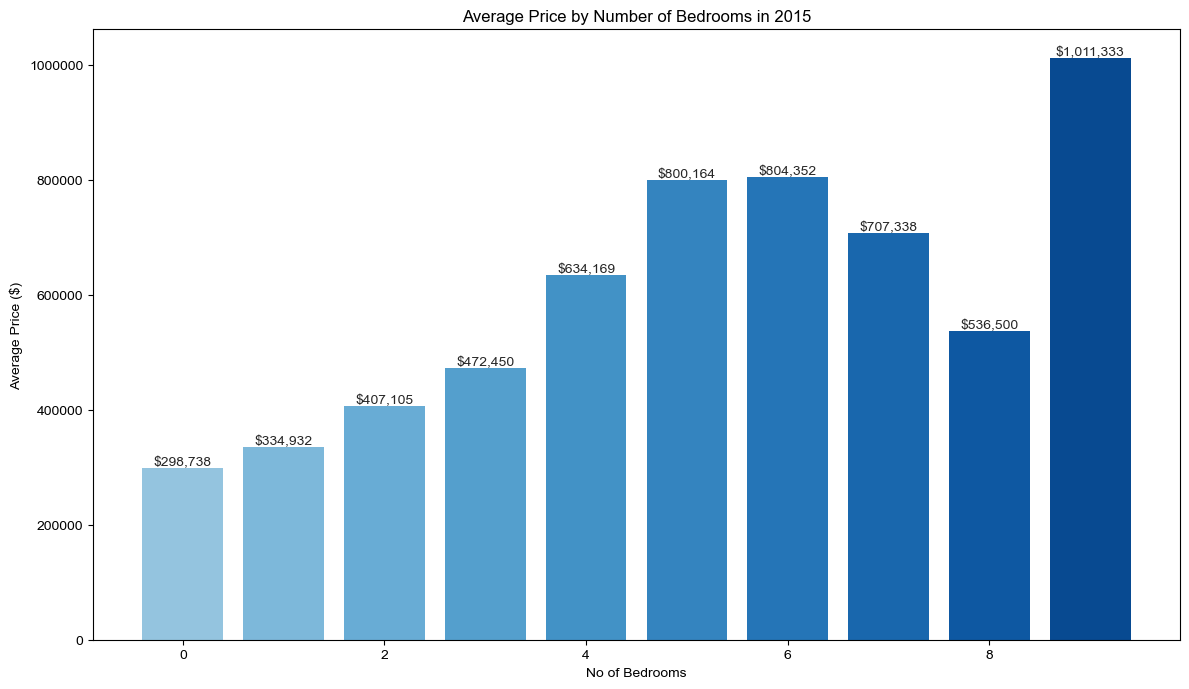

In [11]:
# filter data and apply grouping
filtered_df = df[df['date'].dt.year == 2015]
avg_price = filtered_df.groupby('bedrooms')['price'].mean()

# create figure and plot
plt.figure(figsize=(12, 7))
plt.bar(avg_price.index, avg_price.values, color=plt.cm.Blues(np.linspace(0.4, 0.9, len(avg_price))))
plt.style.use('seaborn-v0_8')

# Value labels on bars
for i, v in enumerate(avg_price.values):
    plt.text(i, v + 5000, f"${v:,.0f}", ha='center', fontsize=10)

# Customise chart
plt.title("Average Price by Number of Bedrooms in 2015")
plt.xlabel("No of Bedrooms")
plt.ylabel("Average Price ($)")
plt.xticks(rotation=0)
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()

plt.show()

The chart shows how average house prices increase with bedroom count in 2015. Prices rise steadily from zero to six bedrooms, reflecting the typical link between home size and value. Beyond six bedrooms, the pattern becomes uneven, with dips at seven and eight before a sharp jump at nine. These fluctuations likely result from fewer high‑bedroom properties, making those averages more sensitive to outliers.

## 2 - How does the sales price change from sales in 2014 compared to sales in 2015?


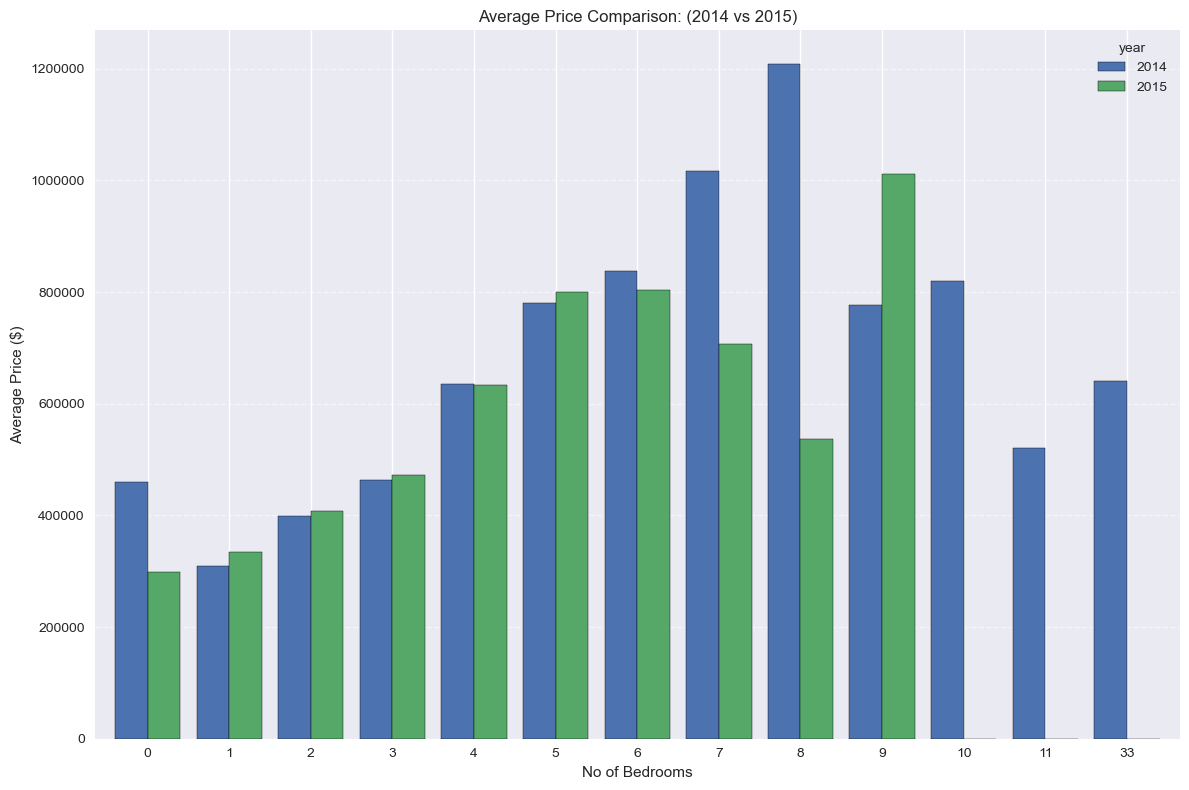

In [12]:
# Extract year
df['year'] = df['date'].dt.year

# Compute averages
pivot_df = df.groupby(["bedrooms", "year"])["price"].mean().unstack()

# create figure and plot
fig, ax = plt.subplots(figsize=(12, 8))
plt.style.use('seaborn-v0_8')
pivot_df.plot(kind="bar", width=0.8, edgecolor="black", ax=ax)

# Customise chart
ax.set_title("Average Price Comparison: (2014 vs 2015)")
ax.set_xlabel("No of Bedrooms")
ax.set_ylabel("Average Price ($)")
ax.ticklabel_format(style="plain", axis="y")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()

The chart compares average house prices in 2014 and 2015 across bedroom counts. Prices generally rise with more bedrooms, reflecting the link between home size and value. Most categories show slightly higher prices in 2015, indicating modest growth. Spikes around 7–9 bedrooms likely reflect luxury properties, while higher bedroom counts may have limited data, making those averages less reliable.

## 3 - Are there seasonal (i.e., monthly) differences in prices? 

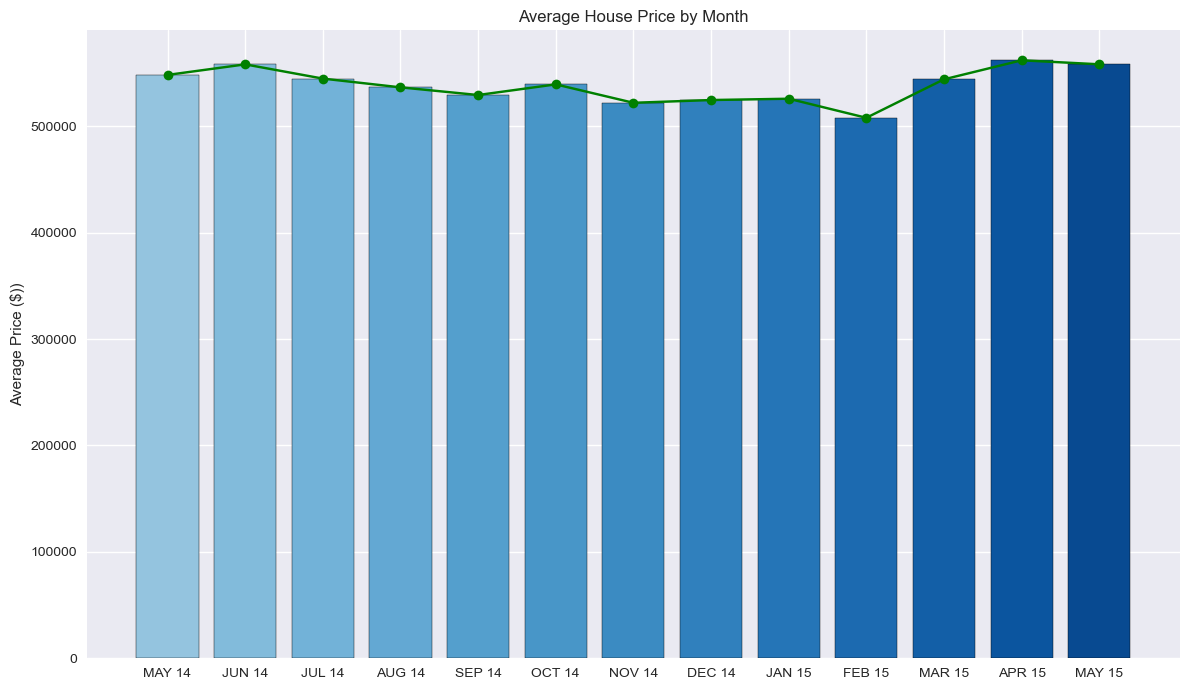

In [13]:
# Create year–month label
df['year_mon'] = df['date'].dt.strftime('%b %y').str.upper()

# Compute average price per month
grouped_data = df.groupby('year_mon')['price'].mean()

# Sort by actual date order (not alphabetical)
grouped_sorted = grouped_data.sort_index(
    key=lambda x: pd.to_datetime(x, format='%b %y')
)

# Create figure and apply style
plt.figure(figsize=(12, 7))
plt.style.use('seaborn-v0_8')

# Plot bar chart + line trend
plt.bar(grouped_sorted.index, grouped_sorted.values,
        color=plt.cm.Blues(np.linspace(0.4, 0.9, len(grouped_sorted))),
        edgecolor="black")

plt.plot(grouped_sorted.index, grouped_sorted.values,
         marker='o', color='green')

# Customise chart
plt.title("Average House Price by Month")
plt.ylabel("Average Price ($))")
plt.xlabel("")
plt.xticks(rotation=0)
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()

plt.show()

Although there appears to be an upward trend from February to May, the evidence is inconclusive because the dataset contains very limited observations for those months in 2014 and 2015. In fact, May is the only month for which both years have available data, which is insufficient to reliably establish or interpret any meaningful trend.

## 4 - Do larger homes tend to have higher prices?

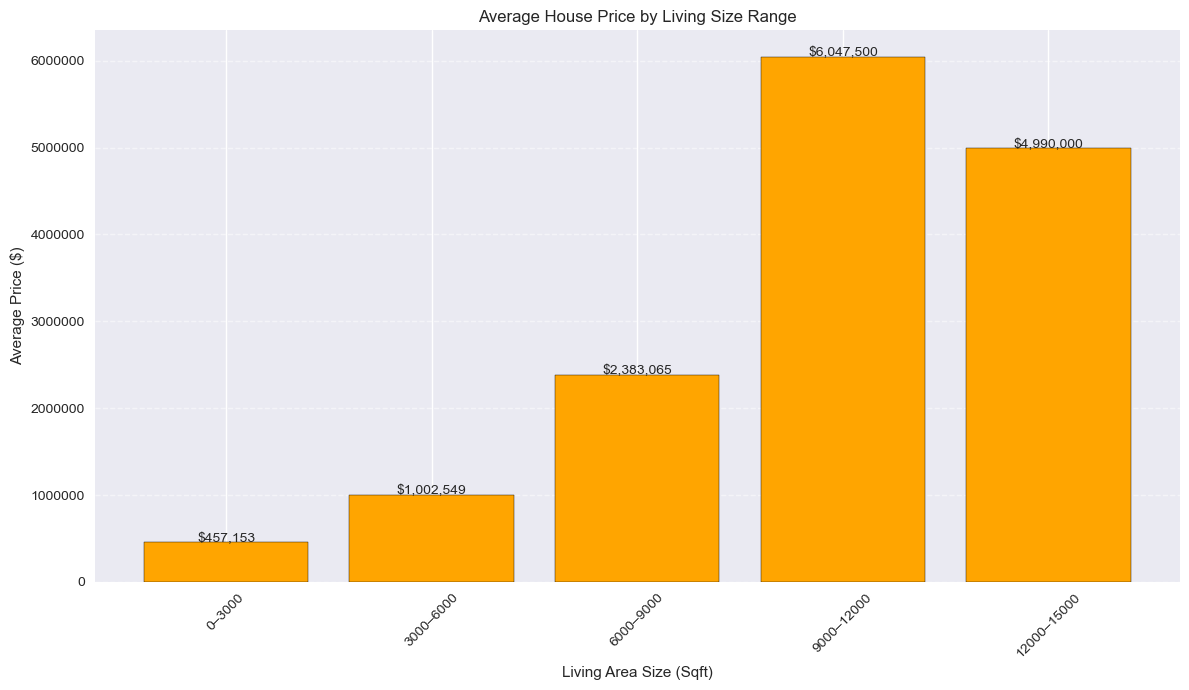

In [14]:

# Define custom bins for sqft
bins = [0, 3000, 6000, 9000, 12000, 15000]
bin_labels = [f"{bins[i]}–{bins[i+1]}" for i in range(len(bins)-1)]

df['living_bin'] = pd.cut(df['sqft_living'], bins=bins, labels=bin_labels, include_lowest=True)

# Compute average price per bin
avg_price_by_bin = df.groupby('living_bin', observed=True)['price'].mean()

# create figure and plot
plt.figure(figsize=(12, 7))
plt.bar(avg_price_by_bin.index.astype(str), avg_price_by_bin.values, color='orange', edgecolor='black')
plt.style.use('seaborn-v0_8')

# Add value labels
for i, v in enumerate(avg_price_by_bin.values):
    plt.text(i, v + 5000, f"${v:,.0f}", ha='center', fontsize=10)

# Customise chart
plt.title("Average House Price by Living Size Range")
plt.xlabel("Living Area Size (Sqft)")
plt.ylabel("Average Price ($)")
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

The chart shows how average house prices rise sharply with larger living‑size ranges. Homes under 3,000 sqft average around `$457,000`, while prices climb steadily through mid‑sized ranges and peak above `$6` million for 9,000–12,000 sqft properties. The slight drop in the largest category suggests fewer ultra‑large homes, making those averages more sensitive to individual high‑value listings.

## 5 - Is there a difference in price between waterfront and non-waterfront properties?

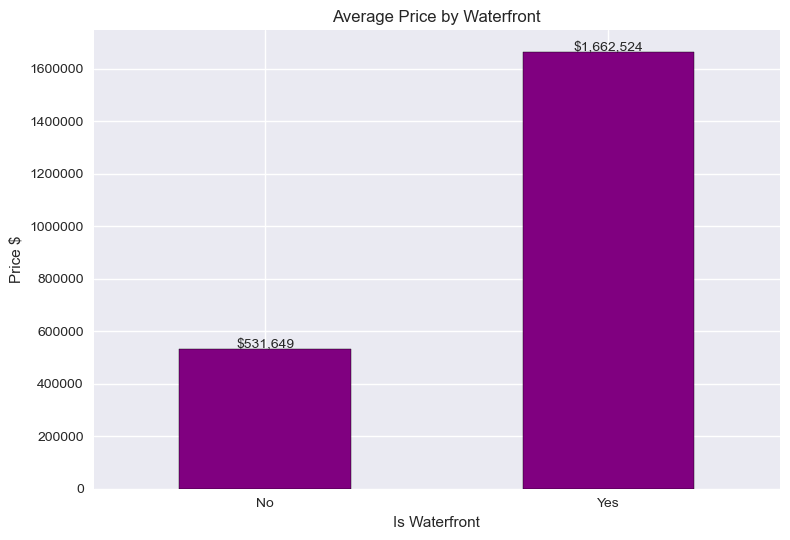

In [15]:

# Group data by bedrooms and return the average
grouped_data = df.groupby('waterfront')['price'].mean()

# Plot the results as a bar chart
grouped_data.plot(kind="bar", color="purple", edgecolor="black")
plt.style.use('seaborn-v0_8')

# Add value labels
for i, v in enumerate(grouped_data.values):
    plt.text(i, v + 5000, f"${v:,.0f}", ha='center', fontsize=10)

# Customise chart
plt.title("Average Price by Waterfront")
plt.xlabel("Is Waterfront")
plt.ylabel("Price $")
plt.xticks(rotation=0)  # Keeps the item names horizontal
plt.ticklabel_format(style="plain", axis="y") 
plt.tight_layout()

plt.show()

The graph shows that homes with waterfront access are dramatically more expensive than those without. Properties without waterfront average around `$550,000`, while waterfront homes exceed `$1.6` million. This large gap highlights the strong premium buyers place on water views and direct access, making waterfront location one of the most influential factors in property value.

## 6 - How does location affects house prices?

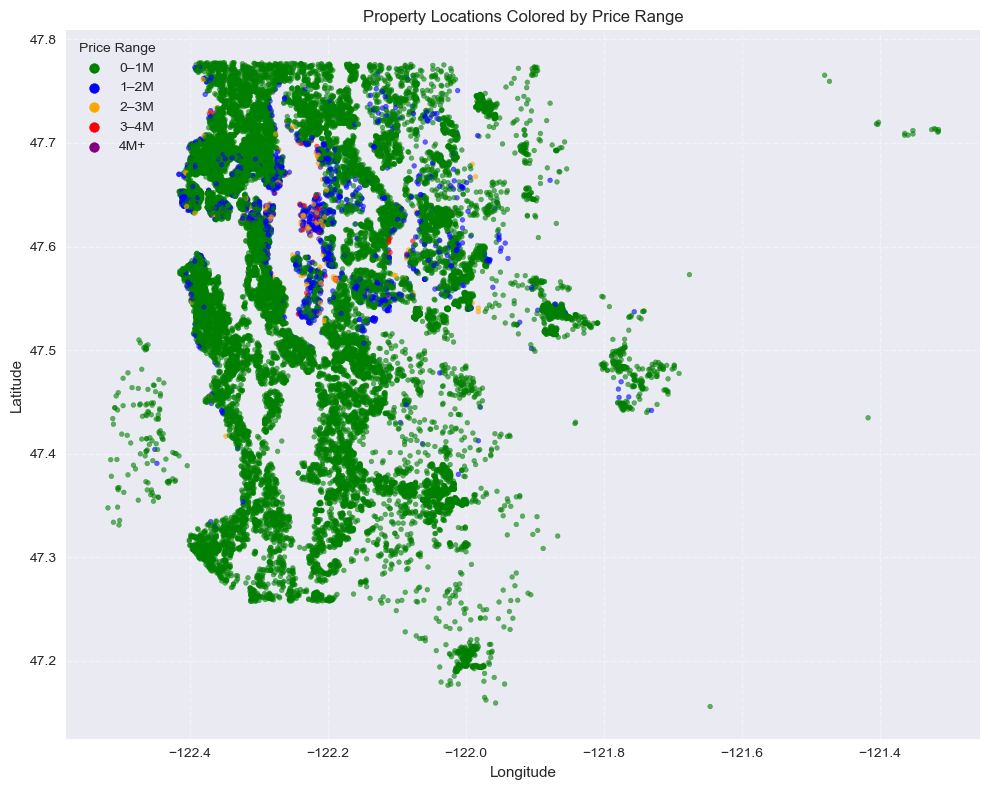

In [16]:
# Define price bins
price_bins = [0, 1_000_000, 2_000_000, 3_000_000, 4_000_000, df['price'].max()]
price_labels = ["0–1M", "1–2M", "2–3M", "3–4M", "4M+"]

df['price_bin'] = pd.cut(df['price'], bins=price_bins, labels=price_labels, include_lowest=True)

# Assign colors to each bin
color_map = {
    "0–1M": "green",
    "1–2M": "blue",
    "2–3M": "orange",
    "3–4M": "red",
    "4M+": "purple"
}

df['color'] = df['price_bin'].map(color_map)

# Scatter plot
plt.figure(figsize=(10, 8))
plt.scatter(df['long'], df['lat'],
            s=12, alpha=0.6,
            c=df['color'])
plt.style.use('seaborn-v0_8')

# Add legend
for label, color in color_map.items():
    plt.scatter([], [], color=color, label=label, s=50)
plt.legend(title="Price Range")

# Customise chart
plt.title("Property Locations Colored by Price Range")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()

plt.show()

The scatter plot shows how property prices vary across locations. Most points are green, indicating many homes fall below $1 million. Higher‑priced properties—blue, orange, red, and purple—appear in tighter clusters, revealing specific areas where values rise sharply. This pattern highlights how location strongly influences price, with premium zones standing out clearly against broader mid and low‑priced regions.

# Section 3 check and address outliers and skewness of all the columns

## Identify numeric columns that is relevant for outliers and skewness 

In [17]:
relevant_datapoints = ['price','sqft_lot','sqft_living']

## Define plotting functions

In [18]:

def draw_plots(datapoint):
    # Create boxplots to identify outliers
    plt.figure(figsize=(16, 8))
    
    plt.subplot(2, 2, 1)
    plt.boxplot(df[datapoint], patch_artist=True)
    plt.title(f'Boxplot of {datapoint.title()}')
    plt.ylabel(datapoint.title())
    plt.ticklabel_format(style="plain", axis="y")
    
    plt.subplot(2, 2, 2)
    plt.hist(df[datapoint], bins=20, edgecolor='black')
    plt.title(f'Histogram of {datapoint.title()}')
    plt.ylabel(datapoint.title())


def draw_skewness_transformations(datapoint):
    # define new column names
    log_name = f'{datapoint}_log'
    sqrt_name = f'{datapoint}_sqrt'
    bc_name = f'{datapoint}_bc'
    
    # Displaying histogram after transformation
    plt.figure(figsize=(10, 6))
    
    plt.subplot(2, 2, 1)
    plt.hist(df[datapoint], bins=30, edgecolor='black')
    plt.title(f'Before Transformation ({datapoint.title()})')
    plt.xlabel(f"skewness: {df[datapoint].skew():.2f}")
    plt.ylabel('Frequency')

    # plot Log transformation
    df[log_name] = np.log(df[datapoint])
    plt.subplot(2, 2, 2)
    plt.hist(df[log_name], bins=30, color='green', edgecolor='black')
    plt.title(f'Log Transformation ({datapoint.title()})')
    plt.xlabel(f"skewness: {df[log_name].skew():.2f}")
    plt.ylabel('Frequency')

    # plot Square Root transformation
    df[sqrt_name] = np.sqrt(df[datapoint])
    plt.subplot(2, 2, 3)
    plt.hist(df[sqrt_name], bins=30, color='red', edgecolor='black')
    plt.title(f'Square Root Transformation ({datapoint.title()})')
    plt.xlabel(f"skewness: {df[sqrt_name].skew():.2f}")
    plt.ylabel('Frequency')

    # plot Box Cox transformation
    df[bc_name], _ = stats.boxcox(df[datapoint] + 1)  # Adding 1 to handle zero values
    plt.subplot(2, 2, 4)
    plt.hist(df[bc_name], bins=30, color='purple', edgecolor='black')
    plt.title(f'Box Cox Transformation ({datapoint.title()})')
    plt.xlabel(f"skewness: {df[bc_name].skew():.2f}")
    plt.ylabel('Frequency')
        
    plt.tight_layout()
    plt.show()

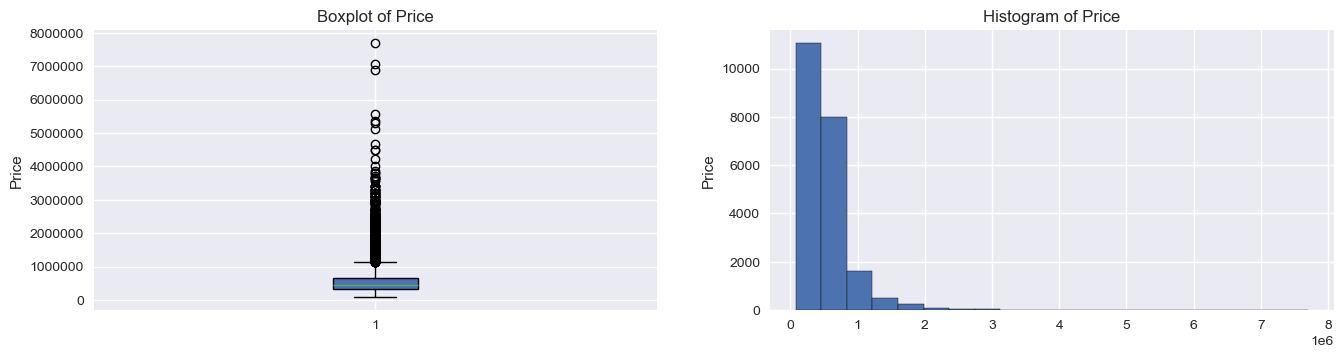

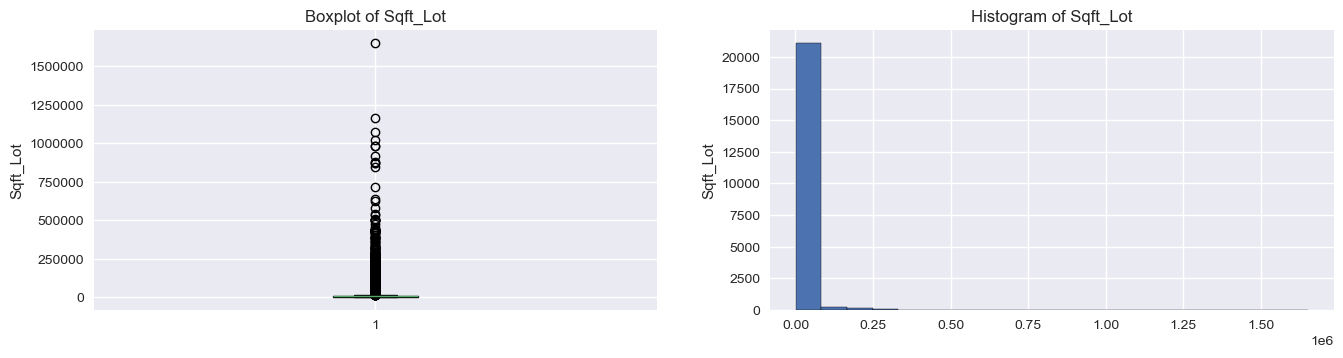

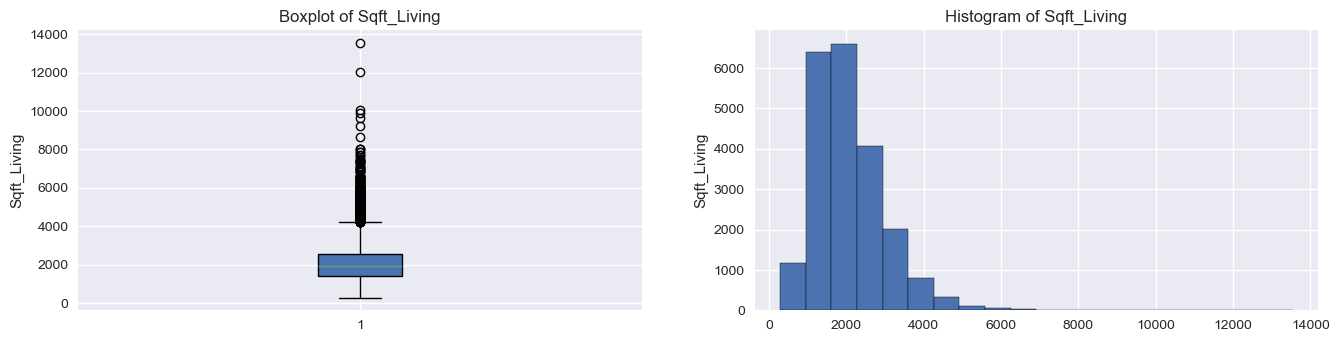

In [19]:
# draw plots before fixing outliers and skewness
for datapoint in relevant_datapoints:
    draw_plots(datapoint)


## Fix outliers first by using median value

In [20]:
for col in relevant_datapoints:
    print("")
    print(f"Column Name:{col}")
    median_val = df[col].median() 
    print(f"median: {median_val}")
    
    #caluclate 25th percentile of leaf length
    percentile25 = df[col].quantile(0.25)
    print(f"percentile25: {percentile25}")

    #caluclate 75th percentile of leaf length
    percentile75 = df[col].quantile(0.75)
    print(f"percentile75: {percentile75}")
    
    #Calculate interquartile range
    iqr = percentile75 - percentile25
    print(f"iqr: {iqr}")

    #calcualte upper and lower thresholds for outliers
    upper_limit = percentile75 + 1.5 *iqr
    lower_limit = percentile25 - 1.5 * iqr

    df_lower = df[df[col] < lower_limit]
    outliers_lower = df_lower[col].tolist()
    df[col] = df[col].replace(outliers_lower, median_val)

    df_higher = df[df[col] > upper_limit]
    outliers_higher = df_higher[col].tolist()
    df[col] = df[col].replace(outliers_higher, median_val)


Column Name:price
median: 450000.0
percentile25: 321500.0
percentile75: 645000.0
iqr: 323500.0

Column Name:sqft_lot
median: 7620.0
percentile25: 5040.0
percentile75: 10695.0
iqr: 5655.0

Column Name:sqft_living
median: 1910.0
percentile25: 1427.0
percentile75: 2550.0
iqr: 1123.0


## Redraw plots after fixing outliers and check if outliers and skewness addressed

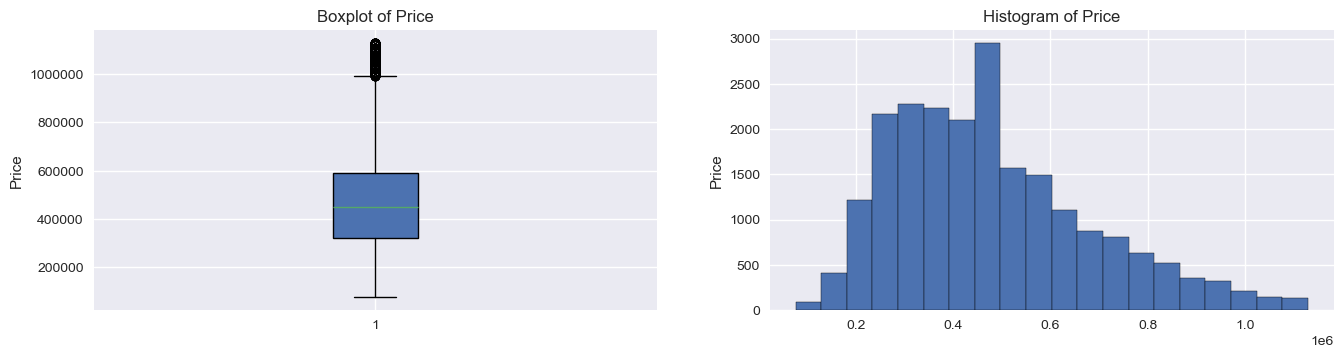

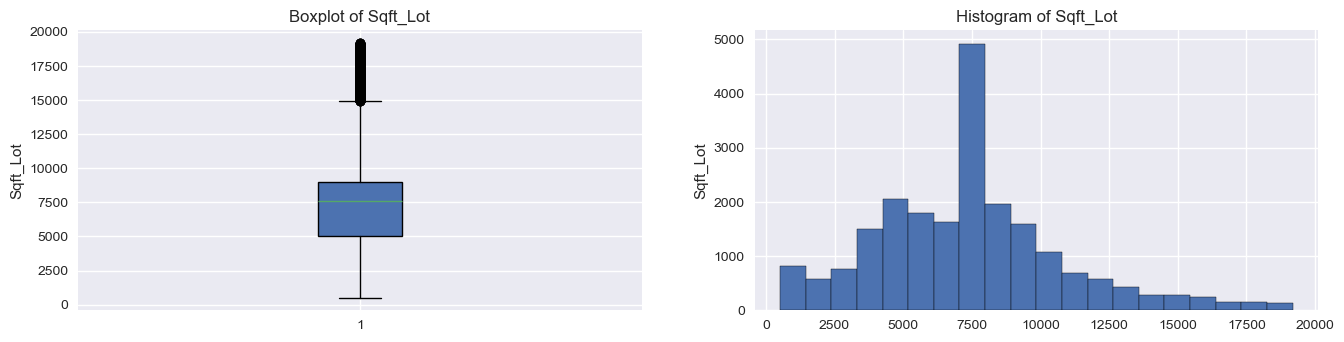

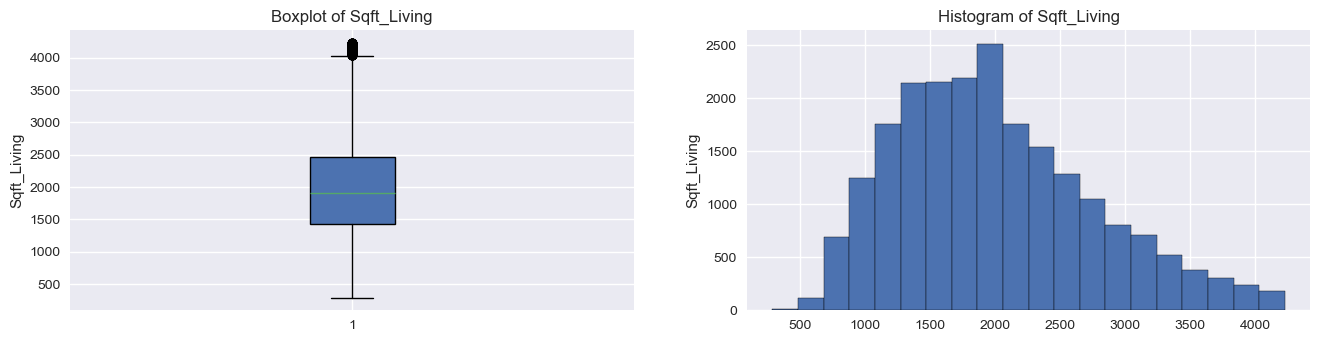

In [21]:
for datapoint in relevant_datapoints:
    draw_plots(datapoint)

## Apply transformations and compare to check which is the best for fixing skewness

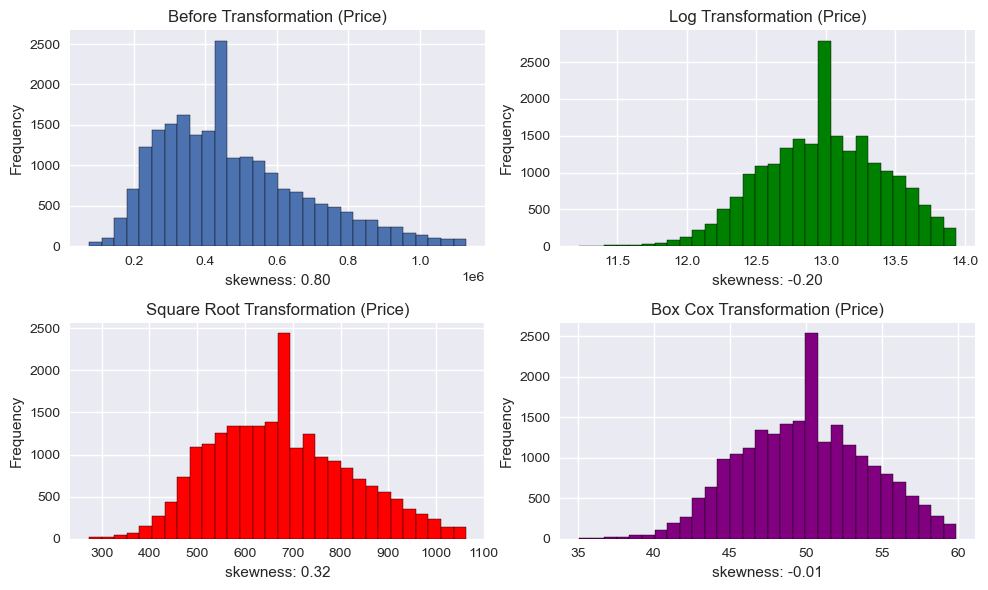

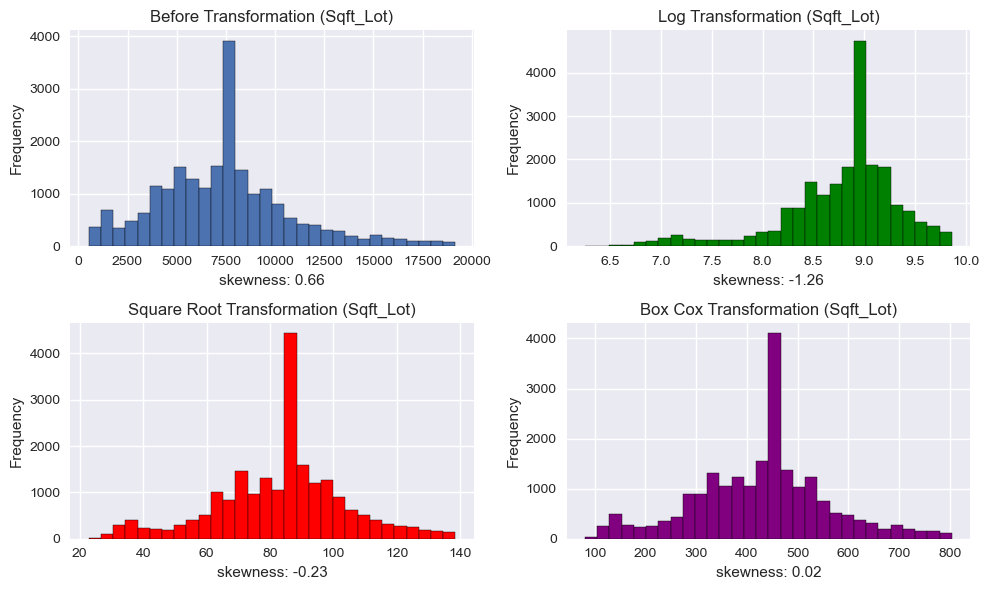

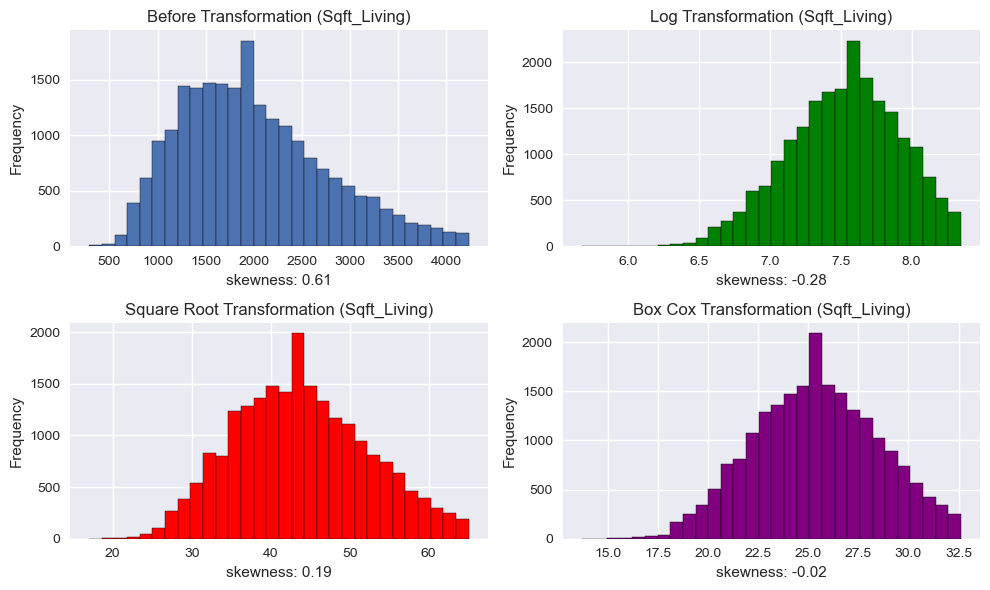

In [22]:
for datapoint in relevant_datapoints:
    draw_skewness_transformations(datapoint)

## Conclusion: 
Looking at the graphs, Box Cox Transformation is the most effective transformation to fix skewness